# Account survey: which accounts does cleaning drop?

Cleaning removes two kinds of things. Broken *rows* are handled by fixed rules
(`cleaning/rules.py`). Whole *accounts* are dropped only when their list cannot be one person's
viewing history, and the cut-offs for that come from the distributions below.

Input: `data/eda/survey/account_stats.parquet`, one row per crawled account, written by
`python -m cleaning.01_survey.account_stats` (raw ratings with the row rules already applied).
The cut-offs chosen here live in `cleaning/config.py`.

How few ratings a user needs to be *useful to a model* is a different question. It is not
decided here: section 6 only reports how many users each minimum would remove.

In [1]:
import json
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parents[1]))

import matplotlib.pyplot as plt
import numpy as np
import polars as pl

from cleaning import accounts, config, plotting
from cleaning.plotting import BLUE, MUTED, ORANGE

plotting.use_style()
pl.Config.set_tbl_rows(20)
pl.Config.set_fmt_str_lengths(80)

stats = accounts.flag_accounts(pl.read_parquet(config.ACCOUNT_STATS)).with_columns(
    watch_days=pl.col("watch_minutes") / 1440,
    n_watched=pl.col("n_completed") + pl.col("n_watching"),
)
print(f"{stats.height:,} accounts, {stats['n_rows'].sum():,} valid rating rows")


def ccdf(values):
    """x sorted ascending, y = share of accounts with a value >= x."""
    x = np.sort(np.asarray(values, dtype=float))
    return x, 1 - np.arange(len(x)) / len(x)

1,907,627 accounts, 553,550,107 valid rating rows


## 1. What the row rules did

These counts are over all raw rows, before any account is dropped.

In [2]:
fixes = json.loads(config.ROW_FIXES.read_text())
rows_in = fixes["rows_in"]
labels = {
    "dropped_no_status": "dropped: no status",
    "dropped_unknown_anime": "dropped: anime not in the catalog",
    "dropped_duplicate": "dropped: repeated (user, anime)",
    "nulled_updated_at": "nulled: updated_at outside 2004 .. crawl end",
    "nulled_start_date": "nulled: start_date partial or out of range",
    "nulled_finish_date": "nulled: finish_date partial or out of range",
    "nulled_episodes_watched": "nulled: episodes_watched above the longest anime",
}
pl.DataFrame({"rule": list(labels.values()),
              "rows": [fixes.get(k, 0) for k in labels],
              "share of rows": [f"{fixes.get(k, 0) / rows_in:.4%}" for k in labels]})

rule,rows,share of rows
str,i64,str
"""dropped: no status""",226323,"""0.0409%"""
"""dropped: anime not in the catalog""",400,"""0.0001%"""
"""dropped: repeated (user, anime)""",13,"""0.0000%"""
"""nulled: updated_at outside 2004 .. crawl end""",3999,"""0.0007%"""
"""nulled: start_date partial or out of range""",1421969,"""0.2568%"""
"""nulled: finish_date partial or out of range""",1288832,"""0.2327%"""
"""nulled: episodes_watched above the longest anime""",7604,"""0.0014%"""


Row-level damage is small: 0.04% of rows are dropped, almost all of them entries MAL returned
without a status. The date columns lose the most values, and nearly all of those are partial
dates (`2015`, `2015-03`) rather than garbage.

## 2. List size

The median account has 177 entries. The distribution is wide on both ends: a long tail of
very large lists, and a large group of accounts with only a handful of entries.

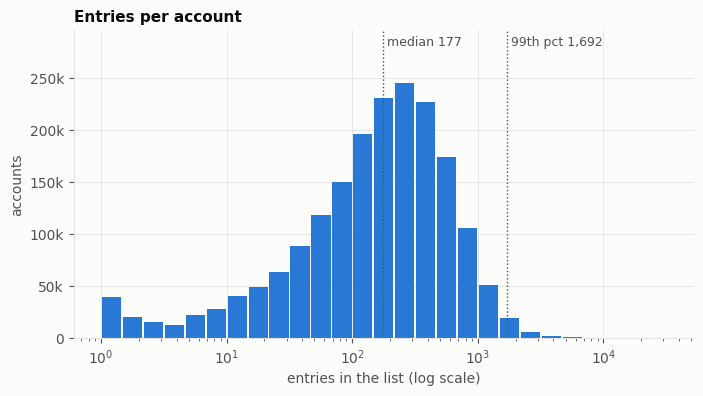

In [3]:
n = stats["n_rows"].drop_nulls().to_numpy()
fig, ax = plt.subplots()
ax.hist(n[n > 0], bins=np.logspace(0, 4.5, 28), color=BLUE, rwidth=0.92)
ax.set_xscale("log")
ax.set_xlabel("entries in the list (log scale)")
ax.set_ylabel("accounts")
ax.set_title("Entries per account")
plotting.thousands(ax)
for q, name in ((0.5, "median"), (0.99, "99th pct")):
    v = np.quantile(n, q)
    ax.axvline(v, color=MUTED, lw=1, ls=":")
    ax.text(v, ax.get_ylim()[1] * 1.13, f" {name} {v:,.0f}", color=MUTED, fontsize=9, va="top")
ax.set_ylim(0, ax.get_ylim()[1] * 1.15)
plt.show()

## 3. Lists too large to be real

The whole MAL catalog is about 30.8k anime. The curves show the share of accounts at or above
each size. The tail gets heavier past a few thousand entries and ends in a cliff at the
catalog size: accounts that added *everything*. There is no sharp break to cut at, so the
cut-off is a round number where a list stops being plausible as one person's history.

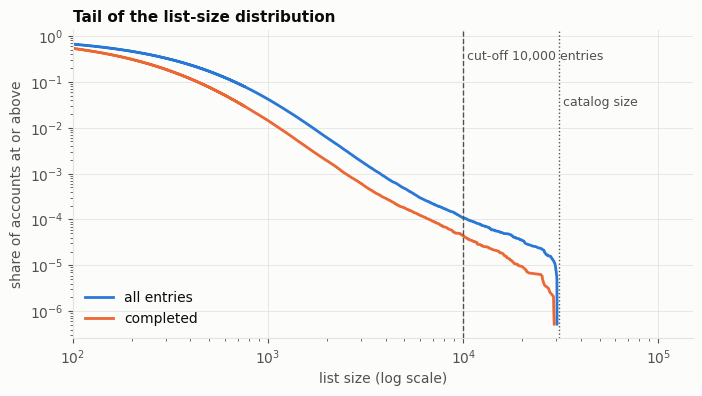

lists with more than  2,000 entries: 11,631 accounts
lists with more than  5,000 entries:    910 accounts
lists with more than 10,000 entries:    208 accounts
lists with more than 20,000 entries:     66 accounts
lists with more than 25,000 entries:     44 accounts


In [4]:
fig, ax = plt.subplots()
for column, label, color in (("n_rows", "all entries", BLUE), ("n_completed", "completed", ORANGE)):
    x, y = ccdf(stats[column].drop_nulls().to_numpy())
    keep = x >= 100
    ax.plot(x[keep], y[keep], color=color, label=label)
ax.axvline(config.MAX_LIST_SIZE, color=MUTED, lw=1, ls="--")
ax.text(config.MAX_LIST_SIZE, 0.3, f" cut-off {config.MAX_LIST_SIZE:,} entries", color=MUTED, fontsize=9)
ax.axvline(30_800, color=MUTED, lw=1, ls=":")
ax.text(30_800, 0.03, " catalog size", color=MUTED, fontsize=9)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlim(100, 150_000)
ax.set_xlabel("list size (log scale)")
ax.set_ylabel("share of accounts at or above")
ax.set_title("Tail of the list-size distribution")
ax.legend(loc="lower left")
plt.show()

for k in (2_000, 5_000, 10_000, 20_000, 25_000):
    print(f"lists with more than {k:>6,} entries: {(stats['n_rows'] > k).sum():>6,} accounts")

**Rule:** drop accounts with more than 10,000 entries (208 accounts). These lists are a third
of the catalog or more, and 66 of them hold over 20,000 entries. Left in, each one would add
tens of thousands of positives and co-occurrence pairs that say nothing about taste.

## 4. Watch time that cannot be real

Watch time is `episodes_watched x episode length`, summed over the list. It catches accounts
with ordinary-looking list sizes but impossible episode counts.

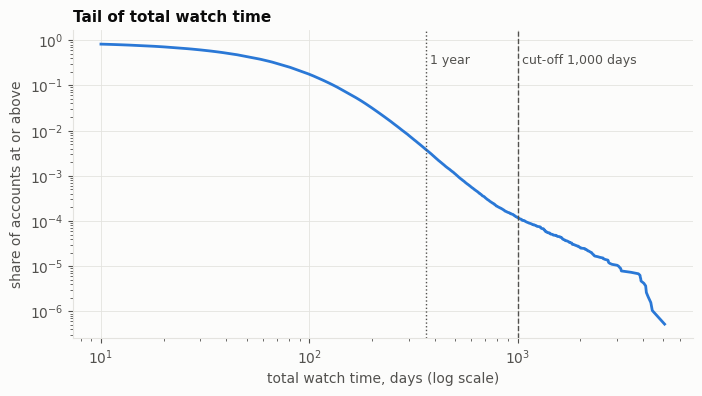

median watch time: 42.0 days
more than   365 days:  7,130 accounts
more than   500 days:  2,124 accounts
more than   730 days:    542 accounts
more than 1,000 days:    229 accounts
more than 2,000 days:     49 accounts


In [5]:
x, y = ccdf(stats["watch_days"].drop_nulls().to_numpy())
keep = x >= 10
fig, ax = plt.subplots()
ax.plot(x[keep], y[keep], color=BLUE)
for days, text in ((365, "1 year"), (config.MAX_WATCH_DAYS, f"cut-off {config.MAX_WATCH_DAYS:,} days")):
    ax.axvline(days, color=MUTED, lw=1, ls="--" if days == config.MAX_WATCH_DAYS else ":")
    ax.text(days, 0.3, f" {text}", color=MUTED, fontsize=9)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("total watch time, days (log scale)")
ax.set_ylabel("share of accounts at or above")
ax.set_title("Tail of total watch time")
plt.show()

print("median watch time:", round(stats["watch_days"].median(), 1), "days")
for k in (365, 500, 730, 1_000, 2_000):
    print(f"more than {k:>5,} days: {(stats['watch_days'] > k).sum():>6,} accounts")

**Rule:** drop accounts with more than 1,000 days of watch time (229 accounts; 75 of them
also break the list-size rule). 1,000 days is 6.6 hours of anime every single day for ten
years. The median account has 42 days, and only 0.03% pass two years.

## 5. Signals that are *not* used to drop accounts

### Bulk additions
Many entries sharing one `updated_at` second means the list was imported or edited by a tool.
That is normal behaviour, not spam, so these accounts stay. It matters later for
sequence models: for these users `updated_at` does not give a watch order.

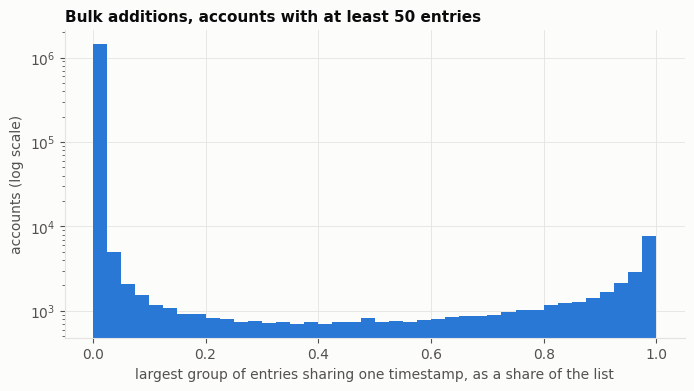

accounts with >= 50 entries: 1,510,990
  at least 10% of the list in one second:  43,015 (2.85%)
  at least 50% of the list in one second:  29,894 (1.98%)
  at least 90% of the list in one second:  14,380 (0.95%)


In [6]:
big = stats.filter(pl.col("n_rows") >= 50)
share = (big["max_rows_per_second"] / big["n_rows"]).drop_nulls().to_numpy()
fig, ax = plt.subplots()
ax.hist(share, bins=40, color=BLUE)
ax.set_yscale("log")
ax.set_xlabel("largest group of entries sharing one timestamp, as a share of the list")
ax.set_ylabel("accounts (log scale)")
ax.set_title("Bulk additions, accounts with at least 50 entries")
plt.show()
print(f"accounts with >= 50 entries: {big.height:,}")
for t in (0.1, 0.5, 0.9):
    print(f"  at least {t:.0%} of the list in one second: {(share >= t).sum():>7,} ({(share >= t).mean():.2%})")

### Scoring behaviour
Some accounts never score, others give every anime the same score. Both are fine as
implicit feedback (the list still says what was watched), so they stay; only models that use
the score value need to care.

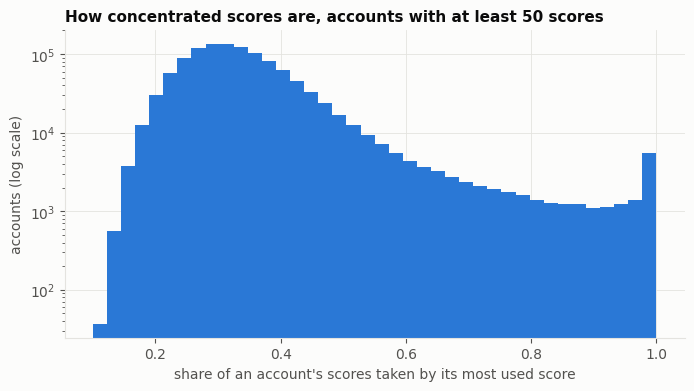

never scored anything: 180,295 accounts (9.5%)
single score for everything (>= 50 scores): 3,267 accounts


In [7]:
never = (stats["n_scored"] == 0).sum()
scored = stats.filter(pl.col("n_scored") >= 50).with_columns(
    mode_share=pl.max_horizontal([pl.col(f"n_score_{k}") for k in range(1, 11)]) / pl.col("n_scored"))
fig, ax = plt.subplots()
ax.hist(scored["mode_share"].to_numpy(), bins=40, color=BLUE)
ax.set_yscale("log")
ax.set_xlabel("share of an account's scores taken by its most used score")
ax.set_ylabel("accounts (log scale)")
ax.set_title("How concentrated scores are, accounts with at least 50 scores")
plt.show()
print(f"never scored anything: {never:,} accounts ({never / stats.height:.1%})")
print(f"single score for everything (>= 50 scores): {(scored['mode_share'] == 1).sum():,} accounts")

## 6. The account rules, and what a minimum-interaction threshold would cost

In [8]:
total_rows = stats["n_rows"].sum()
rows = []
for rule in accounts.RULES + ["dropped"]:
    hit = stats.filter(pl.col(rule))
    rows.append({"rule": "any rule" if rule == "dropped" else rule.replace("rule_", "").replace("_", " "),
                 "accounts": hit.height, "rating rows": hit["n_rows"].sum(),
                 "share of rows": f"{hit['n_rows'].sum() / total_rows:.2%}"})
pl.DataFrame(rows)

rule,accounts,rating rows,share of rows
str,i64,i64,str
"""no valid rows""",7,0,"""0.00%"""
"""list too large""",208,3653085,"""0.66%"""
"""watch time impossible""",229,2361059,"""0.43%"""
"""any rule""",369,4621185,"""0.83%"""


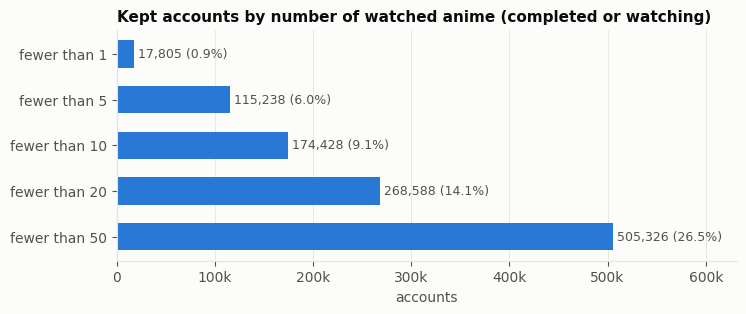

kept: 1,907,258 accounts, 548,928,922 rating rows


In [9]:
kept = stats.filter(~pl.col("dropped"))
thresholds = [1, 5, 10, 20, 50]
below = [(kept["n_watched"] < k).sum() for k in thresholds]
fig, ax = plt.subplots(figsize=(8, 3))
bars = ax.barh([f"fewer than {k}" for k in thresholds], below, color=BLUE, height=0.6)
ax.bar_label(bars, labels=[f" {v:,} ({v / kept.height:.1%})" for v in below], color=MUTED, fontsize=9)
ax.invert_yaxis()
ax.set_xlim(0, max(below) * 1.25)
ax.set_xlabel("accounts")
ax.set_title("Kept accounts by number of watched anime (completed or watching)")
plotting.thousands(ax, "x")
ax.grid(axis="y", visible=False)
plt.show()
print(f"kept: {kept.height:,} accounts, {kept['n_rows'].sum():,} rating rows")

## Outcome

- **Dropped by cleaning:** 369 accounts (0.02%) holding 0.83% of the rows: lists over 10,000
  entries, watch time over 1,000 days, and 7 accounts with no valid row left.
- **Kept, with a caveat:** bulk-imported lists, never-scorers and single-score accounts.
- **Left to the model stage:** small lists. 174k kept accounts (9.1%) have fewer than 10
  watched anime. They are real users (and the product must serve people like them), so
  `data/clean` keeps them and each model applies its own minimum when it builds a split.